# Lab 9 · Pronóstico eléctrico de 150 clientes

Diego y Cisco · CC3092. Notebook final reproducible a partir de artefactos guardados. Restart & Run All no reentrena modelos.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "data.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Ejecutar desde el repositorio DL-LAB09")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from src import data as D, metrics as M, backtest as B
RUN_TRAIN = False  # Cambiar a True solo para generar artefactos que falten.


## 1. Panel y aislamiento temporal

Agregación kW×0.25; train hasta junio, validación julio–septiembre, test octubre–diciembre 2014. Normalización y escala MASE solo con train. Se mantiene la limpieza DST de A para todos los modelos.

In [2]:
panel=D.build_panel()
scale=M.mase_scale(panel)
scaler=D.SeriesScaler().fit(panel)
display(pd.Series({"clientes":panel.unique_id.nunique(),"filas":len(panel),
                   "desde":panel.ds.min(),"hasta":panel.ds.max(),"origenes_test":len(B.daily_origins())}))
assert len(B.daily_origins())==92
assert panel.unique_id.nunique()==150
assert scaler.fit_end==D.TRAIN_END
display(pd.Series(json.loads((ROOT/"outputs"/"runs"/"verification.json").read_text())))

clientes                         150
filas                        3945600
desde            2012-01-01 00:00:00
hasta            2014-12-31 23:00:00
origenes_test                     92
dtype: object

statsforecast_equivalencia_exacta                                                 True
clientes_equivalencia                                                                1
origenes_equivalencia                                                               92
normalizacion_hasta                                                2014-06-30 23:00:00
modelos                              [{'modelo': 'ChronosBolt', 'filas': 331200, 'o...
dtype: object

## 2. Auditoría de los archivos entregados

Cada archivo base tiene exactamente 150×92×24 filas; se comprueba la grilla completa. El archivo combinado se lee por modelo para acotar RAM.

In [3]:
import numpy as np
import pyarrow.parquet as pq
checked=[]
expected_ids=set(panel.unique_id)
for path in sorted((ROOT/"outputs"/"forecasts").glob("*.parquet")):
    if path.stem=="todos":
        continue
    fc=pd.read_parquet(path)
    assert len(fc)==150*92*24, path.name
    assert fc.origin.nunique()==92, path.name
    assert set(fc.unique_id)==expected_ids, path.name
    assert not fc.duplicated(["unique_id","origin","ds"]).any(), path.name
    assert fc.groupby(["unique_id","origin"],observed=True).size().eq(24).all(), path.name
    assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
    assert np.isfinite(fc.y_hat).all(), path.name
    checked.append({"modelo":path.stem,"filas":len(fc)})
display(pd.DataFrame(checked))
combined=pq.ParquetFile(ROOT/"outputs"/"forecasts"/"todos.parquet")
assert combined.metadata.num_rows==sum(r["filas"] for r in checked)
print("Filas combinadas:",combined.metadata.num_rows)

/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.

/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.

/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.

/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.

/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name
/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.

/tmp/ipykernel_211300/861547809.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert ((fc.ds-fc.origin)/pd.Timedelta(hours=1)).between(0,23).all(), path.name


,modelo,filas
0,ChronosBolt,331200
1,DLinear,331200
2,DeepAR,331200
3,LSTM_AR,331200
4,LSTM_Multi,331200
5,LightGBM,331200
6,LightGBM_mensual,331200
7,MLP,331200
8,MSTL,331200
9,NHITS,331200


Filas combinadas: 8611200


## 3. Modelos y métricas en kWh

MASE divide cada MAE entre su escala estacional de train y promedia clientes; WAPE pondera el volumen. MAPE omite consumos ≤0.001. Todos los modelos entrenados se corrieron en una RTX 5070 Laptop; Chronos-Bolt solo hace inferencia (CPU).

In [4]:
tab=pd.read_csv(ROOT/"outputs"/"tables"/"comparacion.csv")
cols=["modelo","L","estrategia","covariables","params_total","params_entrenables","train_s","inference_s","gpu_mem_pico_MB","hardware","MAE","RMSE","WAPE","MAPE","MASE","MASE_navidad"]
display(tab[[c for c in cols if c in tab]].sort_values("MASE"))
name=tab.sort_values("MASE").iloc[0].modelo
fc=pd.read_parquet(ROOT/"outputs"/"forecasts"/f"{name}.parquet")
ev=M.evaluate(fc,panel,scale)
display(pd.Series(ev["resumen"],name=name))
for key in ["MAE","RMSE","MASE","WAPE"]:
    np.testing.assert_allclose(ev["resumen"][key],float(tab.loc[tab.modelo==name,key].iloc[0]),rtol=1e-6)
display(ev["por_h"])
display(ev["por_hora"])

,modelo,L,estrategia,covariables,params_total,params_entrenables,train_s,inference_s,gpu_mem_pico_MB,hardware,MAE,RMSE,WAPE,MAPE,MASE,MASE_navidad
0,iTransformer,168,multi-salida,False,1631256.0,1631256.0,75.655578,16.308844,291.195801,NVIDIA GeForce RTX 5070 Laptop GPU,56.588394,504.324184,0.072407,0.110936,0.808574,1.386156
1,NHITS,168,multi-salida,False,2817570.0,2817570.0,36.224525,11.983267,1217.374023,NVIDIA GeForce RTX 5070 Laptop GPU,56.264221,493.826724,0.071992,0.104830,0.815664,1.524215
2,ChronosBolt,168,zero-shot,False,47718016.0,0.0,0.000000,84.806595,0.000000,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),57.194965,499.018768,0.073183,0.101271,0.817780,1.485922
3,TCN,168,multi-salida,True,271193.0,271193.0,270.012595,12.490655,5854.522461,NVIDIA GeForce RTX 5070 Laptop GPU,56.633057,494.764671,0.072464,0.102512,0.825836,1.519035
4,MLP,168,multi-salida,True,1049626.0,1049626.0,164.607207,13.741018,234.829590,NVIDIA GeForce RTX 5070 Laptop GPU,60.872150,526.179190,0.077888,0.112019,0.852113,1.505720
5,LightGBM,168,recursiva,True,305400.0,305400.0,48.247824,24.734162,NaN,NVIDIA GeForce RTX 5070 Laptop GPU,59.511229,526.230085,0.076147,0.111697,0.867329,1.578303
6,PatchTST,168,multi-salida,False,466843.0,466840.0,148.286248,17.175391,1814.250977,NVIDIA GeForce RTX 5070 Laptop GPU,60.516046,525.857159,0.077432,0.121115,0.882312,1.659568
7,NLinear,168,multi-salida,False,4058.0,4058.0,172.414684,18.147093,205.016602,NVIDIA GeForce RTX 5070 Laptop GPU,65.602371,610.082026,0.083940,0.126794,0.913201,1.826556
8,DLinear,168,multi-salida,False,8114.0,8114.0,77.410107,14.470438,207.175781,NVIDIA GeForce RTX 5070 Laptop GPU,65.155110,603.205365,0.083368,0.126992,0.914124,1.825051
9,MSTL,1344,directa (modelo de estado),False,NaN,NaN,0.000000,434.966248,NaN,NVIDIA GeForce RTX 5070 Laptop GPU,65.823669,571.293823,0.084224,0.125997,0.916753,2.066476


MAE                   56.588394
RMSE                 504.324184
WAPE                   0.072407
MAPE                   0.110936
MAPE_excluidas      2484.000000
MASE                   0.808574
n                 331200.000000
Name: iTransformer, dtype: float64

,MAE,RMSE,WAPE,MASE
1,41.976971,259.734830,0.083597,0.585095
2,45.650344,314.121834,0.105218,0.578113
3,40.712554,280.481848,0.096287,0.548079
4,33.485463,177.244244,0.081235,0.544397
5,32.447182,161.406741,0.079883,0.558234
6,33.306045,160.623504,0.081233,0.621449
7,33.712589,164.961811,0.072374,0.693738
8,34.150553,186.939924,0.066989,0.718309
9,44.151236,244.748987,0.078094,0.782762
10,62.662355,568.936673,0.075690,0.848207


,MAE,RMSE,WAPE,MASE
0,41.976971,259.734830,0.083597,0.585095
1,45.650344,314.121834,0.105218,0.578113
2,40.712554,280.481848,0.096287,0.548079
3,33.485463,177.244244,0.081235,0.544397
4,32.447182,161.406741,0.079883,0.558234
5,33.306045,160.623504,0.081233,0.621449
6,33.712589,164.961811,0.072374,0.693738
7,34.150553,186.939924,0.066989,0.718309
8,44.151236,244.748987,0.078094,0.782762
9,62.662355,568.936673,0.075690,0.848207


## 4. Gráficas y curvas de aprendizaje

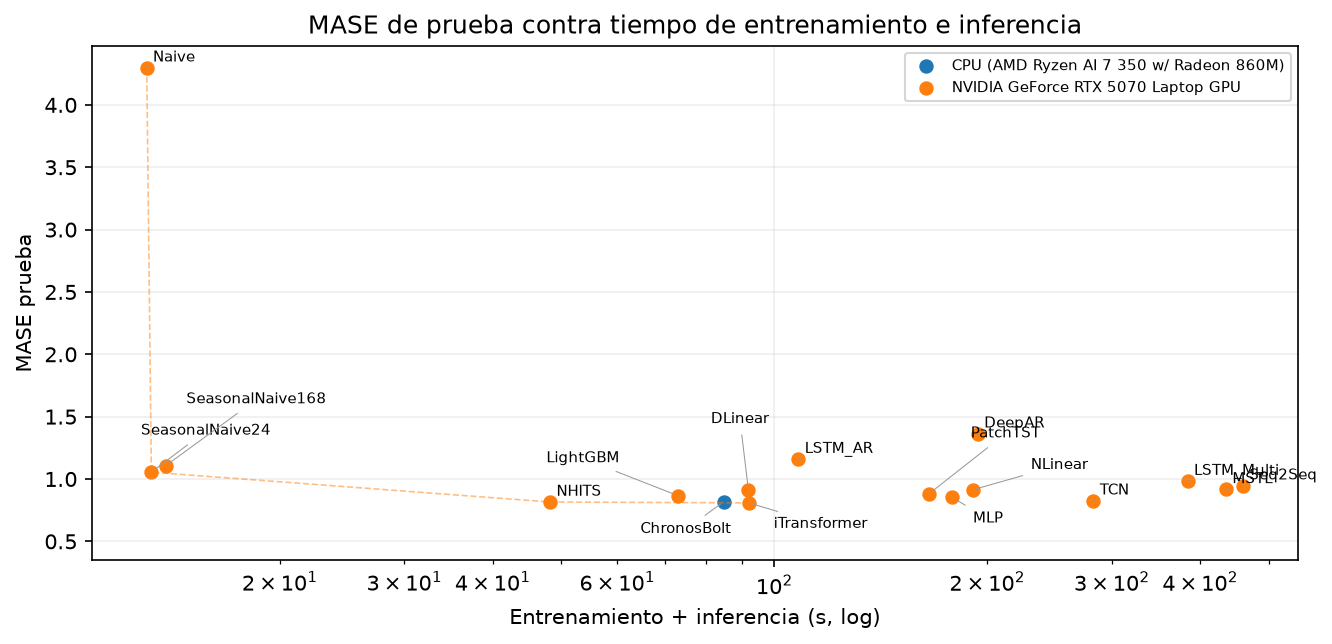

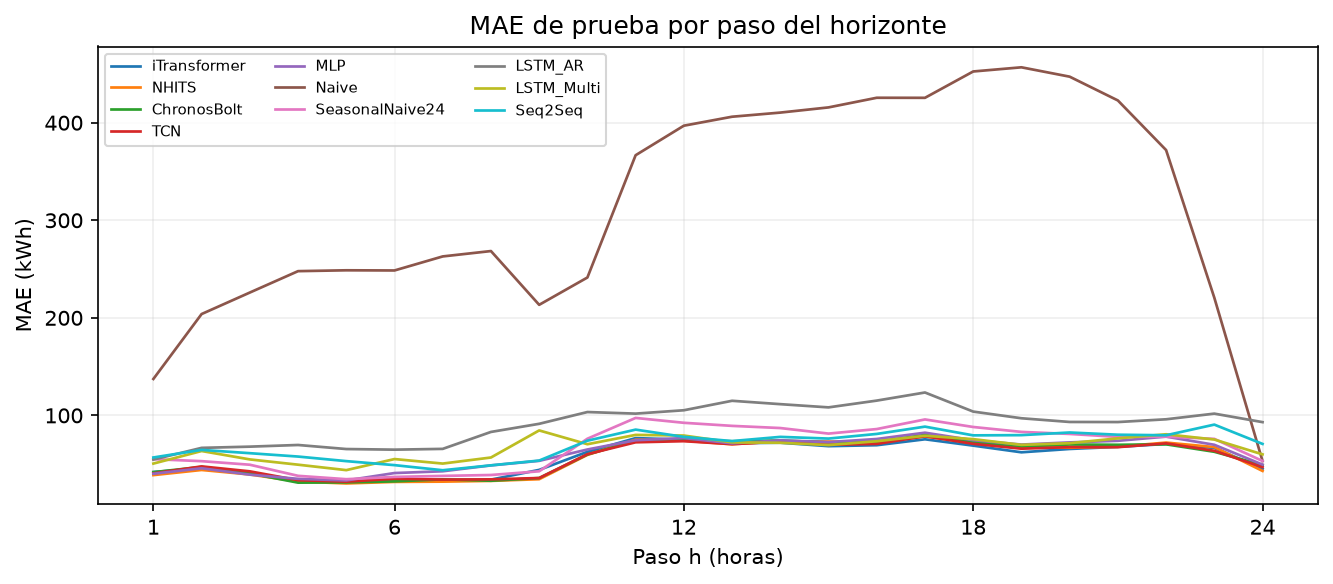

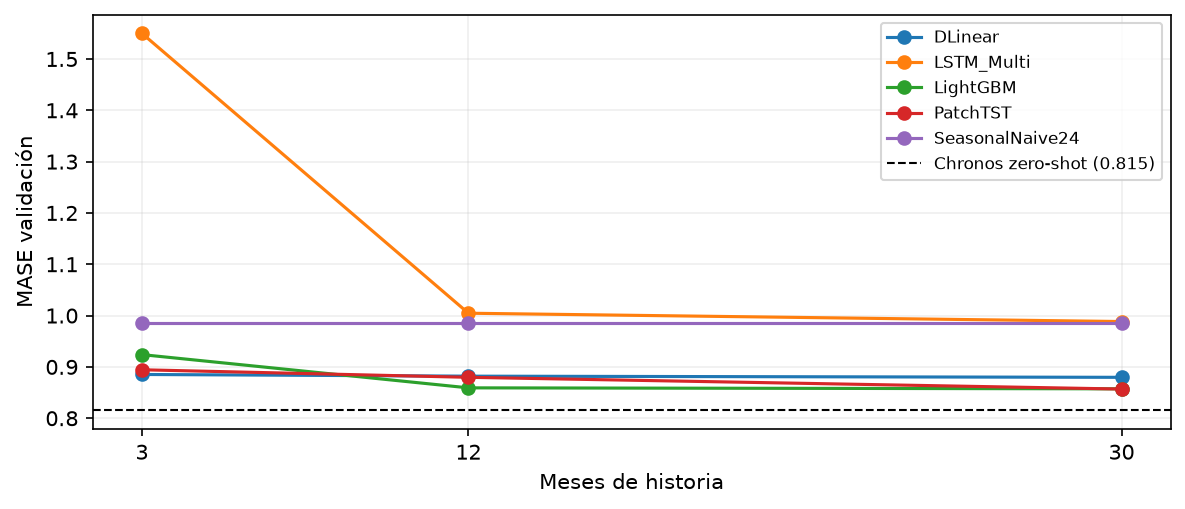

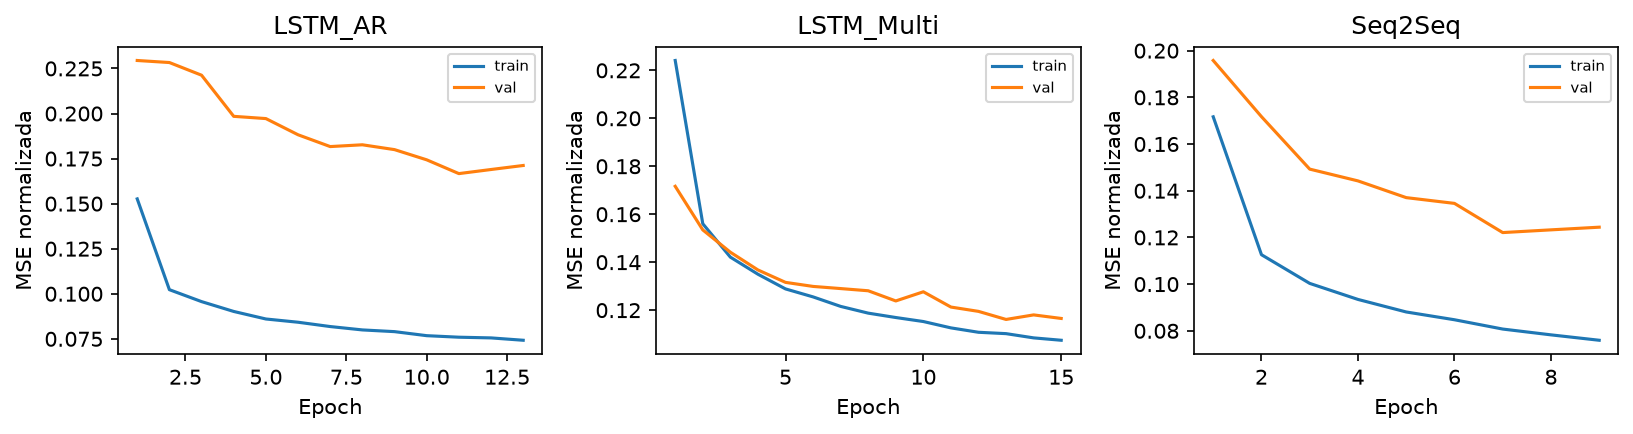

In [5]:
for name in ["pareto","mae_por_h","mase_vs_historia","curvas_recurrentes"]:
    display(Image(filename=str(ROOT/"outputs"/"figs"/f"{name}.png")))

## 5. Experimentos transversales

La selección global del mejor DL considera los MASE de validación de A y B (N-HiTS, 0.799). Las semillas y el reentrenamiento mensual usan su misma arquitectura y presupuesto. Local/global usa diez clientes preseleccionados; no iguala el volumen de información de entrenamiento.

In [6]:
exp=ROOT/"outputs"/"runs"/"experimentos_B"
for name in ["sensibilidad.csv","baseline_L.csv","local_global.csv"]:
    display(pd.read_csv(exp/name))
display(json.loads((exp/"best_dl_selection.json").read_text()))
all_rows=pd.read_csv(ROOT/"outputs"/"tables"/"todos_resultados.csv")
display(all_rows.loc[all_rows.familia.isin(["Semillas","Reentrenamiento"])])
display(all_rows.loc[all_rows.familia=="Semillas",["MAE","MASE"]].agg(["mean","std"]))

,modelo,L,meses,val_MAE,val_MASE,train_s,epochs_max,max_batches_per_epoch
0,LSTM_Multi,48,30,86.283928,1.024582,48.319276,15,1000
1,LSTM_Multi,168,30,81.029434,0.988422,201.889232,15,1000
2,LSTM_Multi,336,30,80.581223,1.018776,284.051895,15,1000
3,LSTM_Multi,168,3,136.849014,1.549986,39.485289,15,1000
4,LSTM_Multi,168,12,83.187691,1.004614,201.398081,15,1000


,modelo,L,L_efectivo,val_MASE,fuente,train_s
0,SeasonalNaive24,48,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
1,SeasonalNaive24,168,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
2,SeasonalNaive24,336,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
3,LightGBM,48,24,0.951847,"B CPU: mismos parámetros de A/historia, sin re...",65.575525
4,LightGBM,168,168,0.857282,"A: barrido_historia.csv; rezagos fijos 1-24,16...",37.143831
5,LightGBM,336,168,0.857282,"A: barrido_historia.csv; rezagos fijos 1-24,16...",37.143831


,alcance,MAE,RMSE,WAPE,MAPE,MAPE_excluidas,MASE,n,train_s,params
0,global_150_evaluado_10,88.802770,289.096354,0.056912,0.104126,0,1.040088,22080,201.889232,111768
1,local_10,115.672086,348.134082,0.074132,0.186111,0,1.582074,22080,11.120306,1117680


{'criterio': 'MASE validación, todas las familias A y B',
 'mejor': {'modelo': 'NHITS',
  'hardware': 'NVIDIA GeForce RTX 5070 Laptop GPU',
  'inference_s': 11.983267244999297,
  'familia': 'Convolucionales',
  'L': 168,
  'estrategia': 'multi-salida',
  'covariables': False,
  'params_total': 2817570,
  'params_entrenables': 2817570,
  'train_s': 36.22452499700012,
  'pasos_seleccion': 1500,
  'pasos_final': 1500,
  'val_MASE': 0.7989026611705128,
  'validation_step_size': 24,
  'gpu_mem_pico_MB': 1217.3740234375,
  'MAE': 56.26422083662647,
  'RMSE': 493.82672427611243,
  'WAPE': 0.07199188883560259,
  'MAPE': 0.1048301982687758,
  'MASE': 0.815663903814208,
  'MASE_navidad': 1.5242147343864587},
 'candidatos': [{'modelo': 'NLinear', 'val_MASE': 0.8778082728385925},
  {'modelo': 'DLinear', 'val_MASE': 0.8797428607940674},
  {'modelo': 'MLP', 'val_MASE': 0.8200646042823792},
  {'modelo': 'PatchTST', 'val_MASE': 0.8568459874851447},
  {'modelo': 'iTransformer', 'val_MASE': 0.8079002902

,modelo,hardware,inference_s,familia,L,estrategia,covariables,train_s,model_id,load_s,...,train_s_search_total,seed,hidden,epochs,max_batches_per_epoch,arboles,seleccion,params_referencia,nota,pasos
0,NHITS_seed7,NVIDIA GeForce RTX 5070 Laptop GPU,12.394872,Semillas,168,multi-salida,False,18.225615,NaN,NaN,...,NaN,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0
1,NHITS_seed123,NVIDIA GeForce RTX 5070 Laptop GPU,12.481867,Semillas,168,multi-salida,False,18.482134,NaN,NaN,...,NaN,123.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0
3,NHITS_mensual,NVIDIA GeForce RTX 5070 Laptop GPU,11.668495,Reentrenamiento,168,mensual expandible,False,56.998578,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0
4,NHITS_seed42,NVIDIA GeForce RTX 5070 Laptop GPU,12.272632,Semillas,168,multi-salida,False,18.055412,NaN,NaN,...,NaN,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0
10,LightGBM_mensual,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),25.454578,Reentrenamiento,168,mensual expandible,True,270.994094,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,validación; configuración congelada antes de p...,"Conteo del modelo de diciembre, reconstruido c...",NaN,NaN


,MAE,MASE
mean,55.687066,0.807781
std,0.557154,0.006390


## 6. Incertidumbre y Navidad

Intervalos nominales de 80%, pinball por cuantil y cobertura observada. Bolt usa reordenamiento monótono. No se prueba exclusión de Electricity de su preentrenamiento.

,modelo,pinball_q10,pinball_q50,pinball_q90,pinball,cobertura_P10_P90
0,ChronosBolt,14.289627,28.597485,14.023352,18.970154,0.812014
1,DeepAR,25.354999,52.464436,24.332086,34.050507,0.673904


,modelo,MAE,RMSE,WAPE,MAPE,MAPE_excluidas,MASE,n,pinball_q10,pinball_q50,pinball_q90,pinball,cobertura_P10_P90
0,iTransformer,76.409066,498.543985,0.114835,0.199215,377,1.386156,25200,NaN,NaN,NaN,NaN,NaN
2,ChronosBolt,87.164665,575.908630,0.131000,0.180033,377,1.485922,25200,35.158493,43.582333,18.103628,32.281487,0.721468
10,Seq2Seq,95.436124,619.507310,0.143431,0.215278,377,1.499650,25200,NaN,NaN,NaN,NaN,NaN
4,MLP,87.401617,531.094721,0.131356,0.192074,377,1.505720,25200,NaN,NaN,NaN,NaN,NaN
3,TCN,85.840933,546.773507,0.129010,0.202144,377,1.519035,25200,NaN,NaN,NaN,NaN,NaN
1,NHITS,85.907718,570.050205,0.129111,0.211660,377,1.524215,25200,NaN,NaN,NaN,NaN,NaN
5,LightGBM,92.915579,587.891006,0.139643,0.217239,377,1.578303,25200,NaN,NaN,NaN,NaN,NaN
11,LSTM_Multi,96.829279,557.483340,0.145525,0.228422,377,1.633981,25200,NaN,NaN,NaN,NaN,NaN
6,PatchTST,95.164885,587.828476,0.143023,0.230770,377,1.659568,25200,NaN,NaN,NaN,NaN,NaN
13,SeasonalNaive168,84.746239,605.726562,0.127365,0.272050,377,1.661288,25200,NaN,NaN,NaN,NaN,NaN


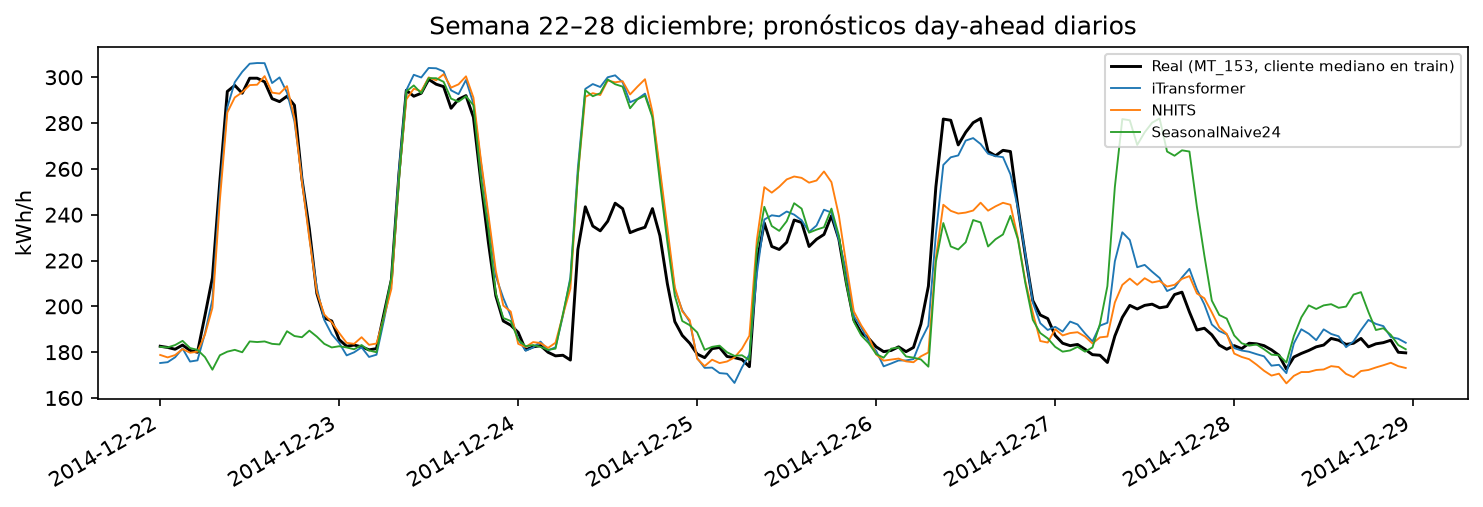

In [7]:
display(pd.read_csv(ROOT/"outputs"/"tables"/"probabilistica.csv"))
display(pd.read_csv(ROOT/"outputs"/"tables"/"navidad.csv").sort_values("MASE"))
display(Image(filename=str(ROOT/"outputs"/"figs"/"semana_navidad_comparacion.png")))

## 7. Reproducibilidad y discusión

El código pesado vive en `src/`. `python -m src.run_cisco --stage all` genera las etapas faltantes y reutiliza resultados guardados. En GPU, las recurrentes usan hasta 15 epochs de 1,000 batches de 512 ventanas y N-HiTS, TCN y DeepAR hasta 1,500 pasos de 1,024 ventanas, el mismo presupuesto que los modelos de la parte A. El informe está en `informe/informe.pdf`.